In [37]:
%load_ext autoreload
%autoreload 2
import torch
from IPython import display
from matplotlib import pyplot as plt
import dl_utils
import numpy as np


batch_size = 256
train_iter, test_iter = dl_utils.load_data_fashion_mnist(batch_size)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:
num_inputs = 28*28
num_outputs = 10

W = torch.normal(0, 0.01, size=(num_inputs, num_outputs), requires_grad=True)
b = torch.zeros(num_outputs, requires_grad=True)


In [39]:
X = torch.tensor([[1.0, 2.0,3.0],[4.0, 5.0, 6.0]])
X.sum(0, keepdim=True), X.sum(1, keepdim=True)

(tensor([[5., 7., 9.]]),
 tensor([[ 6.],
         [15.]]))

In [40]:
X.shape, X.sum(0, keepdim=True).shape

(torch.Size([2, 3]), torch.Size([1, 3]))

In [41]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1, keepdim=True)
    return X_exp / partition

In [42]:
X = torch.normal(0, 1, (2, 5))
X_prob = softmax(X)
X_prob, X_prob.sum(1)

(tensor([[0.0392, 0.2375, 0.1872, 0.2100, 0.3261],
         [0.0971, 0.3500, 0.0795, 0.4163, 0.0569]]),
 tensor([1.0000, 1.0000]))

In [43]:
def net(X):
    return softmax(torch.matmul(X.reshape((-1, W.shape[0])),W) + b)

In [44]:
y= torch.tensor([0, 2])
y_hat = torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])
y_hat[[0, 1], y]

tensor([0.1000, 0.5000])

In [45]:
def cross_entropy(y_hat, y):
    return - torch.log(y_hat[range(len(y_hat)), y])

cross_entropy(y_hat, y)

tensor([2.3026, 0.6931])

In [46]:
dl_utils.accuracy(y_hat, y) / len(y)

0.5

In [47]:
import importlib

importlib.invalidate_caches()
importlib.reload(dl_utils)

<module 'dl_utils' from 'd:\\Github\\Self_project\\Algorithms_Research_Lab\\Algorithms_Research_Lab\\docs\\notes\\deep_learning\\pytorch\\2-linear_nerual_network\\dl_utils.py'>

In [48]:
dl_utils.evaluate_accuracy(net, test_iter)

0.0777

In [49]:
lr = 0.1
def updater(batch_size):
    return dl_utils.sgd([W, b], lr, batch_size)

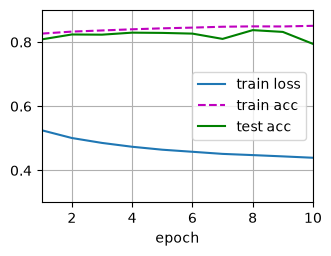

In [54]:
num_epochs = 10
dl_utils.train_ch3(net, train_iter, test_iter, cross_entropy, num_epochs, updater)

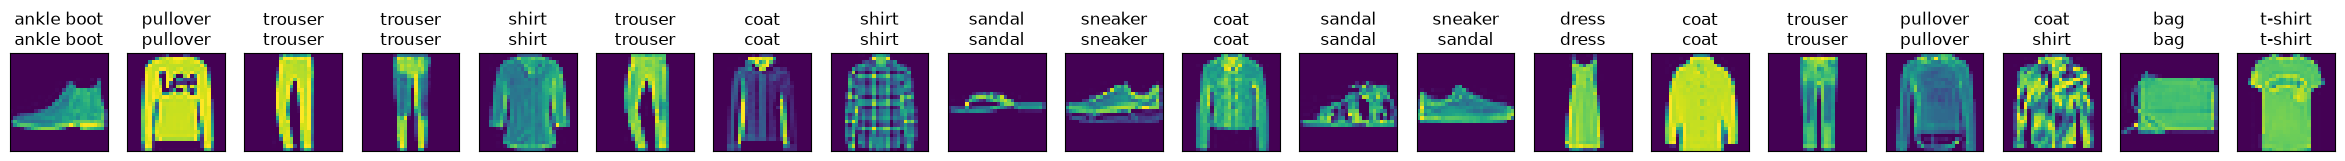

In [58]:
dl_utils.predict_ch3(net, test_iter, 20)